In [11]:
import os, time, random, math
import numpy as np
import pandas as pd
import cv2
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

ROOT = "/kaggle/input/competitions/nppe-1-dl-gen-ai-course-semantic-segmentation/Dataset"          # folder containing metadata.csv, train/, test/
SIZE = 384
CLASSES = ["hex_nut", "washer", "bolt", "ball_bearing", "spring", "o_ring"]
CLASS_ID = {c: i + 1 for i, c in enumerate(CLASSES)}   
NUM_CLASSES = len(CLASSES) + 1                         

BATCH_SIZE = 8
EPOCHS = 40
LR = 3e-4
VAL_FRAC = 0.15
SEED = 0
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", DEVICE)

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
set_seed()





device: cuda


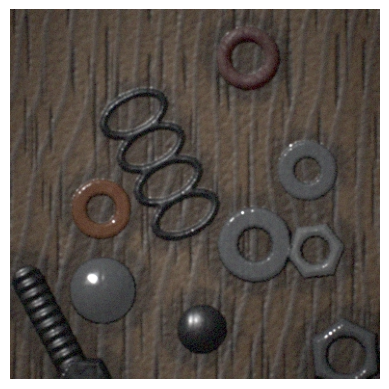

In [12]:
from PIL import Image
import matplotlib.pyplot as plt
img = Image.open("/kaggle/input/competitions/nppe-1-dl-gen-ai-course-semantic-segmentation/Dataset/train/images/img_00000.png").convert("RGB")

plt.imshow(img)
plt.axis("off")
plt.show()

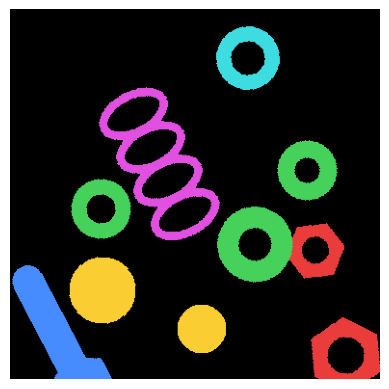

In [13]:
from PIL import Image
import matplotlib.pyplot as plt
img = Image.open("/kaggle/input/competitions/nppe-1-dl-gen-ai-course-semantic-segmentation/Dataset/train/masks/img_00000.png").convert("RGB")

plt.imshow(img)
plt.axis("off")
plt.show()

In [14]:

DATASET_PATH = "/kaggle/input/competitions/nppe-1-dl-gen-ai-course-semantic-segmentation/Dataset"

TRAIN_IMAGE_DIR = os.path.join(DATASET_PATH, "train/images")
TRAIN_MASK_DIR = os.path.join(DATASET_PATH, "train/masks")

TEST_IMAGE_DIR = os.path.join(DATASET_PATH, "test/images")

METADATA_PATH = os.path.join(DATASET_PATH, "metadata.csv")
TRAIN_CSV_PATH = os.path.join(DATASET_PATH, "train/train.csv")
SUBMISSION_PATH = os.path.join(DATASET_PATH, "sample_submission.csv")

In [15]:
train_images = sorted(os.listdir(TRAIN_IMAGE_DIR))

train_masks = sorted(os.listdir(TRAIN_MASK_DIR))

test_images = sorted(os.listdir(TEST_IMAGE_DIR))

print("Training Images :", len(train_images))
print("Training Masks :", len(train_masks))
print("Testing Images :", len(test_images))

In [16]:
index = random.randint(0, len(train_images)-1)

image_name = train_images[index]

image = np.array(Image.open(os.path.join(TRAIN_IMAGE_DIR, image_name)))

mask = np.array(Image.open(os.path.join(TRAIN_MASK_DIR, image_name)))

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.imshow(image)
plt.title(image_name)
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(mask, cmap="tab10")
plt.title("Mask")
plt.axis("off")

plt.show()

In [20]:
images, masks = next(iter(train_loader))

print(images.shape)
print(masks.shape)

In [21]:
class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(out_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class UpBlock(nn.Module):
    def __init__(self, in_channels, skip_channels, out_channels):
        super().__init__()

        self.up = nn.ConvTranspose2d(
            in_channels,
            out_channels,
            kernel_size=2,
            stride=2
        )

        self.conv = ConvBlock(
            out_channels + skip_channels,
            out_channels
        )

    def forward(self, x, skip):

        x = self.up(x)

        x = torch.cat([x, skip], dim=1)

        x = self.conv(x)

        return x


class CustomSegCNN(nn.Module):

    def __init__(self, num_classes=7):
        super().__init__()


        self.enc1 = ConvBlock(3, 32)
        self.pool1 = nn.MaxPool2d(2)

        self.enc2 = ConvBlock(32, 64)
        self.pool2 = nn.MaxPool2d(2)

        self.enc3 = ConvBlock(64, 128)
        self.pool3 = nn.MaxPool2d(2)

        self.enc4 = ConvBlock(128, 256)
        self.pool4 = nn.MaxPool2d(2)

 
        self.bottleneck = ConvBlock(256, 512)

  
        self.up1 = UpBlock(
            in_channels=512,
            skip_channels=256,
            out_channels=256
        )

        self.up2 = UpBlock(
            in_channels=256,
            skip_channels=128,
            out_channels=128
        )

        self.up3 = UpBlock(
            in_channels=128,
            skip_channels=64,
            out_channels=64
        )

        self.up4 = UpBlock(
            in_channels=64,
            skip_channels=32,
            out_channels=32
        )

        self.final = nn.Conv2d(
            32,
            num_classes,
            kernel_size=1
        )

    def forward(self, x):

   
        e1 = self.enc1(x)
        x = self.pool1(e1)

        e2 = self.enc2(x)
        x = self.pool2(e2)

        e3 = self.enc3(x)
        x = self.pool3(e3)

        e4 = self.enc4(x)
        x = self.pool4(e4)


        x = self.bottleneck(x)

        x = self.up1(x, e4)
        x = self.up2(x, e3)
        x = self.up3(x, e2)
        x = self.up4(x, e1)


        x = self.final(x)

        return x

In [23]:
class DiceLoss(nn.Module):
    def __init__(self, smooth=1e-6):
        super().__init__()
        self.smooth = smooth

    def forward(self, outputs, targets):

        
        outputs = torch.softmax(outputs, dim=1)

        
        targets = torch.nn.functional.one_hot(
            targets,
            num_classes=outputs.shape[1]
        ).permute(0, 3, 1, 2).float()

        intersection = (outputs * targets).sum(dim=(2, 3))
        union = outputs.sum(dim=(2, 3)) + targets.sum(dim=(2, 3))

        dice = (2 * intersection + self.smooth) / (union + self.smooth)

        return 1 - dice.mean()

In [24]:

class CombinedLoss(nn.Module):
    def __init__(self):
        super().__init__()
        self.ce = nn.CrossEntropyLoss()
        self.dice = DiceLoss()

    def forward(self, outputs, targets):
        return 0.4 * self.ce(outputs, targets) + 0.6 * self.dice(outputs, targets)

criterion = CombinedLoss()

criterion = CombinedLoss()
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=EPOCHS
)

In [ ]:
images, masks = next(iter(train_loader))

images = images.to(DEVICE)
masks = masks.to(DEVICE)

outputs = model(images)

loss = criterion(outputs, masks)

print("Output Shape :", outputs.shape)
print("Mask Shape   :", masks.shape)
print("Loss         :", loss.item())

In [ ]:
def train_one_epoch(model, dataloader, optimizer, criterion, device):

    model.train()

    running_loss = 0.0

    for images, masks in tqdm(dataloader, desc="Training"):

        images = images.to(device)
        masks = masks.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, masks)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

    epoch_loss = running_loss / len(dataloader)

    return epoch_loss

In [ ]:
CLASSES = ["hex_nut", "washer", "bolt", "ball_bearing", "spring", "o_ring"]
CLASS_ID = {c: i + 1 for i, c in enumerate(CLASSES)}
SIZE = 384

In [ ]:
def validate_one_epoch(model, dataloader, criterion, device):

    model.eval()

    running_loss = 0.0

    pred_masks = []
    gt_masks = []

    with torch.no_grad():

        for images, masks in tqdm(dataloader, desc="Validation"):

            images = images.to(device)
            masks = masks.to(device)

            outputs = model(images)

            loss = criterion(outputs, masks)

            running_loss += loss.item()

            preds = torch.argmax(outputs, dim=1)

            pred_masks.extend(preds.cpu().numpy())
            gt_masks.extend(masks.cpu().numpy())

    val_loss = running_loss / len(dataloader)

    val_dice = mean_dice(pred_masks, gt_masks)

    return val_loss, val_dice

In [ ]:
best_dice = 0.0

train_losses = []
val_losses = []
val_dices = []

for epoch in range(EPOCHS):

    print(f"\nEpoch [{epoch+1}/{EPOCHS}]")


    train_loss = train_one_epoch(
        model,
        train_loader,
        optimizer,
        criterion,
        DEVICE
    )


    val_loss, val_dice = validate_one_epoch(
        model,
        val_loader,
        criterion,
        DEVICE
    )

   
    scheduler.step()


    train_losses.append(train_loss)
    val_losses.append(val_loss)
    val_dices.append(val_dice)

    print(f"Train Loss : {train_loss:.4f}")
    print(f"Val Loss   : {val_loss:.4f}")
    print(f"Mean Dice  : {val_dice:.4f}")

  
    if val_dice > best_dice:
        best_dice = val_dice
        torch.save(model.state_dict(), "best_unet.pth")
        print(f"Model Saved! Best Dice: {best_dice:.4f}")

In [ ]:
plt.figure(figsize=(10,5))

plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title("Training Curve")

plt.legend()

plt.show()

In [ ]:
plt.figure(figsize=(10,5))
plt.plot(val_dices, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Mean Dice")
plt.title("Validation Mean Dice")
plt.grid(True)
plt.show()

In [ ]:
# model = CustomSegCNN(num_classes=NUM_CLASSES).to(DEVICE)

# model.load_state_dict(torch.load("best_custom_cnn.pth", map_location=DEVICE))

# model.eval()

In [ ]:

model.load_state_dict(
    torch.load("best_unet.pth", map_location=DEVICE)
)

model.eval()

In [ ]:
class TestDataset(Dataset):

    def __init__(self, image_dir, image_list, transform=None):

        self.image_dir = image_dir
        self.image_list = image_list
        self.transform = transform

    def __len__(self):
        return len(self.image_list)

    def __getitem__(self, idx):

        image_name = self.image_list[idx]

        image = np.array(
            Image.open(
                os.path.join(self.image_dir, image_name)
            ).convert("RGB")
        )

        if self.transform:
                image = self.transform(image=image)["image"]

        return image, image_name

In [ ]:
test_transform = A.Compose([
    A.Normalize(
        mean=(0.485,0.456,0.406),
        std=(0.229,0.224,0.225)
    ),
    ToTensorV2()
])

In [ ]:
test_dataset = TestDataset(
    TEST_IMAGE_DIR,
    test_images,
    test_transform
)

test_loader = DataLoader(
    test_dataset,
    batch_size=4,
    shuffle=False
)

In [ ]:
predictions = {}



with torch.no_grad():

    for images, image_names in tqdm(test_loader):

        images = images.to(DEVICE)

    
        probs = torch.softmax(model(images), dim=1)


        images_h = torch.flip(images, dims=[3])
        probs_h = torch.softmax(model(images_h), dim=1)


        probs_h = torch.flip(probs_h, dims=[3])


        probs = (probs + probs_h) / 2


        preds = torch.argmax(probs, dim=1).cpu().numpy()

        for mask, name in zip(preds, image_names):
            predictions[name] = mask

In [ ]:
def rle_encode(mask):
    px = np.asarray(mask, np.uint8).T.flatten()
    px = np.concatenate([[0], px, [0]])
    runs = np.where(px[1:] != px[:-1])[0] + 1
    runs[1::2] -= runs[::2]
    return " ".join(str(int(x)) for x in runs)


In [ ]:


def load_label(root, fid, split="train"):
    """Masks store the class id as the pixel value, with a display palette attached.

    np.array() returns the 0-6 label map. Never call .convert("RGB") on these.
    """
    return np.array(Image.open(f"{root}/{split}/masks/{fid}"))


In [ ]:
def rle_decode(rle, size=SIZE):
    m = np.zeros(size * size, np.uint8)
    if not isinstance(rle, str) or not rle.strip():
        return m.reshape(size, size, order="F")
    a = np.asarray(rle.split(), np.int64)
    for s, l in zip(a[0::2], a[1::2]):
        m[s - 1: s - 1 + l] = 1
    return m.reshape(size, size, order="F")

In [ ]:
pred_labels = []
ids = []

for image_name in test_images:
    pred_labels.append(predictions[image_name])
    ids.append(image_name)

In [ ]:
print("Unique values in first prediction:", np.unique(pred_labels[0]))

print("Prediction shape:", pred_labels[0].shape)

print("Total predictions:", len(pred_labels))

In [ ]:
def write_submission(pred_labels, ids, path):
    rows = []

    for fid, lab in zip(ids, pred_labels):
        for c in CLASSES:
            m = (lab == CLASS_ID[c])

            if m.any():
                rle = rle_encode(m)
            else:
                print(f"Empty mask found for {fid}_{c}")   
                rle = "1 1"

            rows.append({
                "ImageId_ClassId": f"{fid}_{c}",
                "EncodedPixels": rle
            })

    pd.DataFrame(rows).to_csv(path, index=False)

In [ ]:
write_submission(
    pred_labels,
    ids,
    "submission.csv"
)

In [ ]:
submission = pd.read_csv(
    "submission.csv",
    keep_default_na=False
)
submission.isnull().sum()

In [ ]:
submission = pd.read_csv("submission.csv", keep_default_na=False)

print(
    submission.loc[
        submission["ImageId_ClassId"] == "img_01957.png_o_ring"
    ]
)

In [ ]:
submission = pd.read_csv("submission.csv", keep_default_na=False)

print("Empty strings:", (submission["EncodedPixels"] == "").sum())

In [ ]:
submission = pd.read_csv("submission.csv", keep_default_na=False)

empty_rows = submission[submission["EncodedPixels"] == ""]

print(empty_rows)

In [ ]:
idx = ids.index("img_01957.png")

mask = pred_labels[idx]

print(np.unique(mask))
print(np.sum(mask == CLASS_ID["o_ring"]))

In [ ]:
submission = pd.read_csv("submission.csv", keep_default_na=False)

print("Rows:", len(submission))
print("Empty strings:", (submission["EncodedPixels"] == "").sum())
print("Nulls:\n", submission.isnull().sum())
print("Duplicate IDs:", submission["ImageId_ClassId"].duplicated().sum())